# Лабораторная работа № 1
## Задание №2
> Григорьев Никита M3338, Паховский Иван M3339


## 1. Дисперсия выборочного среднего и медианы

$X \sim (1-\varepsilon)\mathcal{N}(\mu,\sigma^{2}) + \varepsilon \mathcal{N}(\mu,\tau^{2})$

### Дисперсия выборочного среднего

$Var(X) = (1-\varepsilon) \sigma^{2} + \varepsilon \tau^{2}$

$Var(\overline{X}) = Var(\frac{1}{n} \sum_{i=1}^n X_i) = \frac{1}{n^2} \sum_{i=1}^n Var(X_i) = \frac{1}{n} Var(X) = \frac{1}{n} ((1-\varepsilon) \sigma^{2} + \varepsilon \tau^{2})$

### Асимптотическая дисперсия медианы

1) Воспользуемся **Теоремой об асимптотике средних членов вариационного ряда.**

$$
\frac{
\sqrt n\left(X_{(\lceil np\rceil)}-q_p\right)
}{
\sqrt{p(1-p)}/f(q_p)
}
\overset d\longrightarrow
\mathcal N(0,1),
\qquad n\to\infty.
$$

$$
\widehat q_p=X_{(\lceil np\rceil)}.
$$


$$
\sqrt n\left(\widehat q_p-q_p\right)
\overset d\longrightarrow
\mathcal N\left(
0,
\frac{p(1-p)}{f(q_p)^2}
\right).
$$

$$
p(1-p)=0.5\cdot0.5=\frac14.
$$


$$
\sqrt n\left(\widehat q_{0.5}-q_{0.5}\right)
\overset d\longrightarrow
\mathcal N\left(
0,
\frac{1}{4f(q_{0.5})^2}
\right).
$$


$$
\sqrt n\left(\widehat q_{0.5}-q_{0.5}\right) \overset d\longrightarrow N\left(
0,
\frac{1}{4f(q_{0.5})^2}
\right).
$$


$$
\widehat q_{0.5}-q_{0.5} \overset d\longrightarrow \frac{N\left(
0,
\frac{1}{4f(q_{0.5})^2}
\right)}{\sqrt n}.
$$


$$
\widehat q_{0.5}
\overset d\longrightarrow
q_{0.5}+\frac{N\left(
0,
\frac{1}{4f(q_{0.5})^2}
\right)}{\sqrt n}.
$$


$$
\operatorname{Var}\left(\frac{N\left(
0,
\frac{1}{4f(q_{0.5})^2}
\right)}{\sqrt n}\right) = \frac{1}{n}\operatorname{Var}(N\left(
0,
\frac{1}{4f(q_{0.5})^2}
\right)),
$$


$$
\operatorname{Var}(\widehat q_{0.5})
\approx
\frac{1}{n}
\cdot
\frac{1}{4f(q_{0.5})^2}.
$$

2) Нужно найти теоретическую медиану:
$$F(x) = (1-\varepsilon) \Phi\left(\frac{x-\mu}{\sigma}\right) + \varepsilon \Phi\left(\frac{x-\mu}{\tau}\right),$$

$$F(\mu) = (1-\varepsilon)\Phi(0) +\varepsilon\Phi(0) = (1-\varepsilon)\cdot\frac{1}{2} +\varepsilon\cdot\frac{1}{2} = \frac{1}{2} = F(q_{0.5})$$

т.е. $$ q_{0.5} = \mu$$

тогда $$\operatorname{Var}(\operatorname{Med}(X))\approx\frac{1}{4n\left((1-\varepsilon)\frac{1}{\sqrt{2\pi\sigma^2}}+\varepsilon\frac{1}{\sqrt{2\pi\tau^2}}\right)^2}.$$



In [81]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

PARAMS = [{"n" : 10000, "var1" : 2, "var2" : 100},
          {"n" : 10000, "var1" : 10, "var2" : 500},
          {"n" : 10000, "var1" : 100, "var2" : 10000},
          {"n" : 10000, "var1" : 0.1, "var2" : 150}]



In [82]:
def theor_var(n, sigma_sqr, gamma_sqr, epsilon):
    return ((1 - epsilon) * sigma_sqr + epsilon * gamma_sqr)

def n_sample_median_var(n, sigma_sqr, gamma_sqr, epsilon):
    return 1 / (4 * ((1 - epsilon) * (1 / np.sqrt(2 * np.pi * sigma_sqr)) + epsilon * (1 / np.sqrt(2 * np.pi * gamma_sqr))) ** 2)

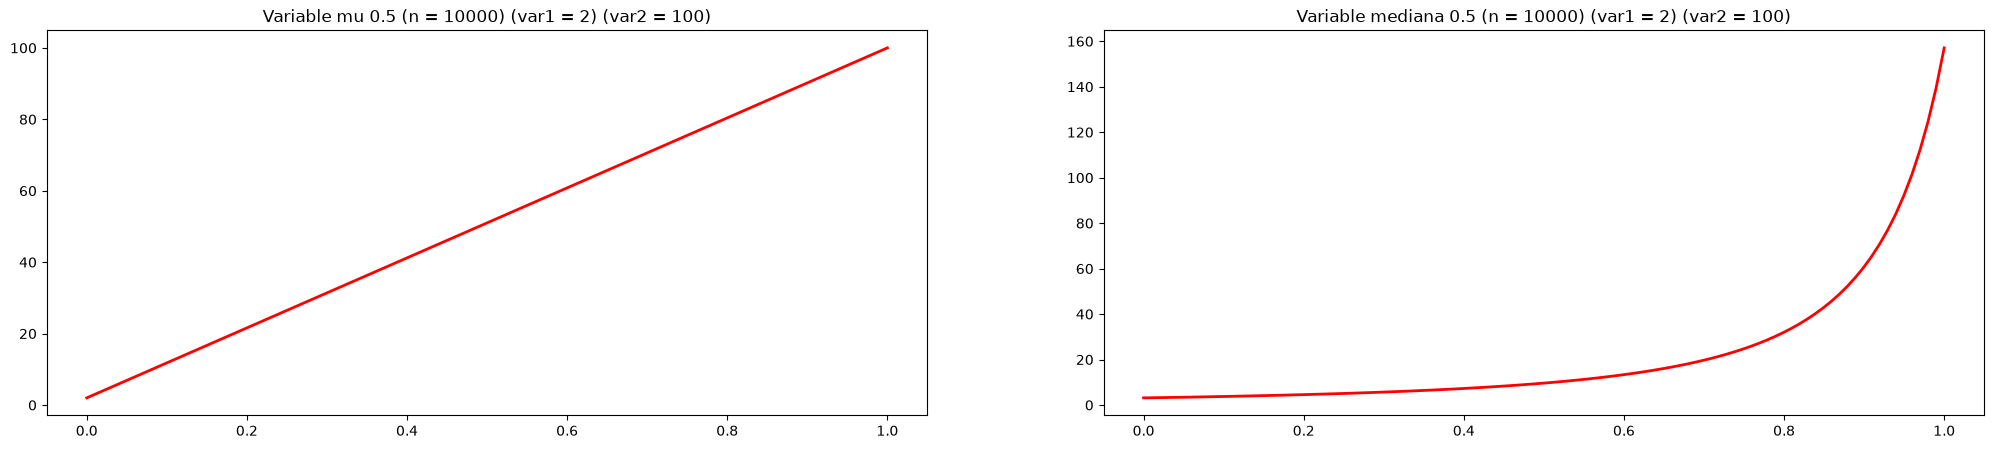

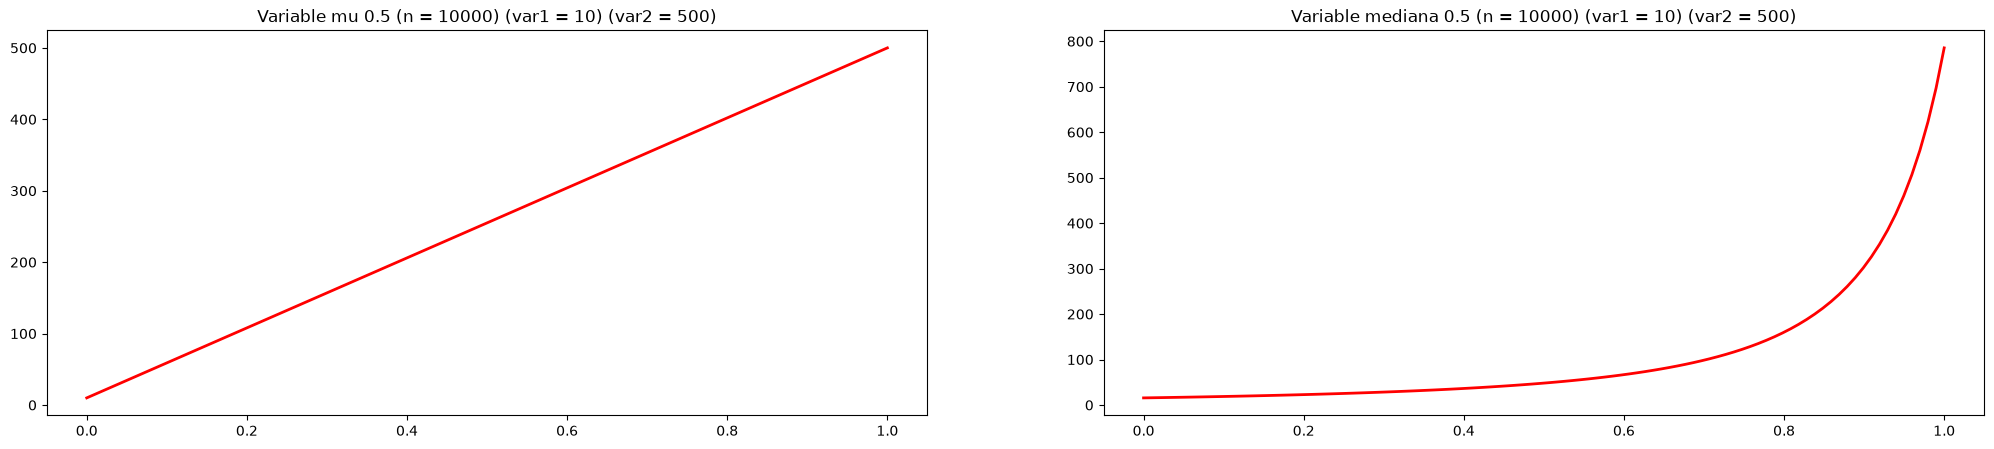

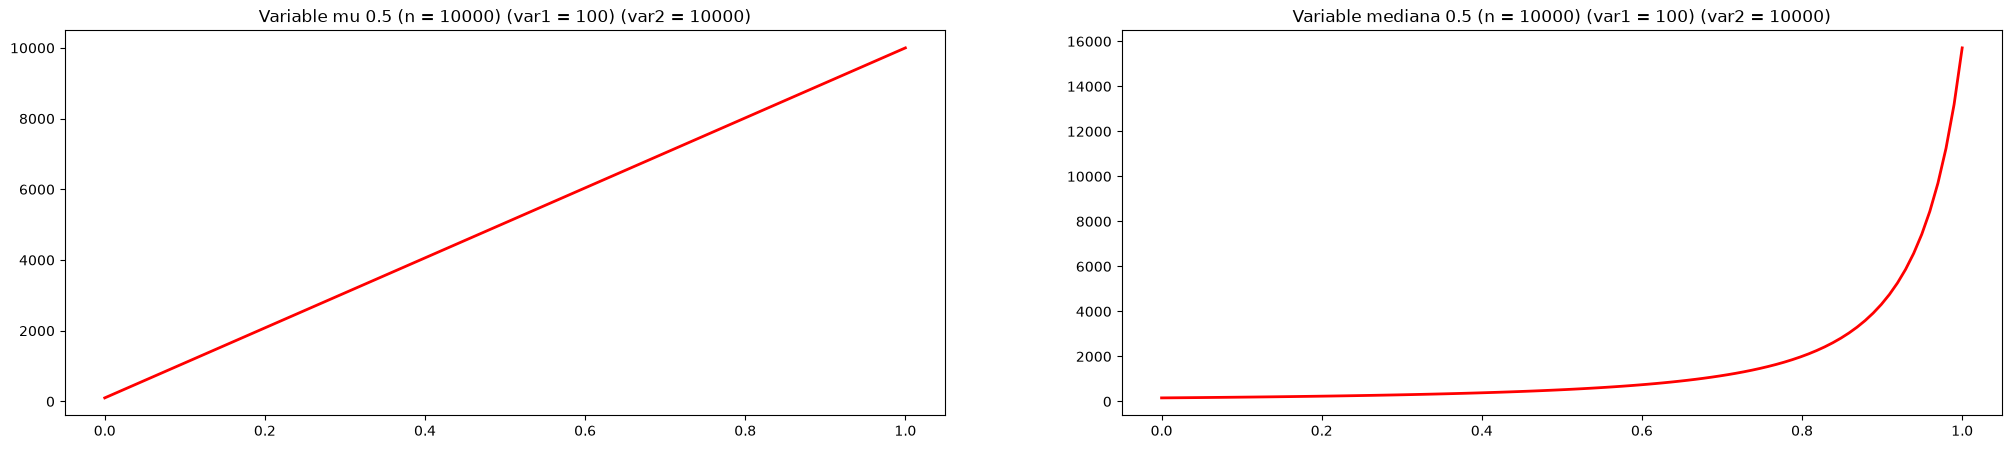

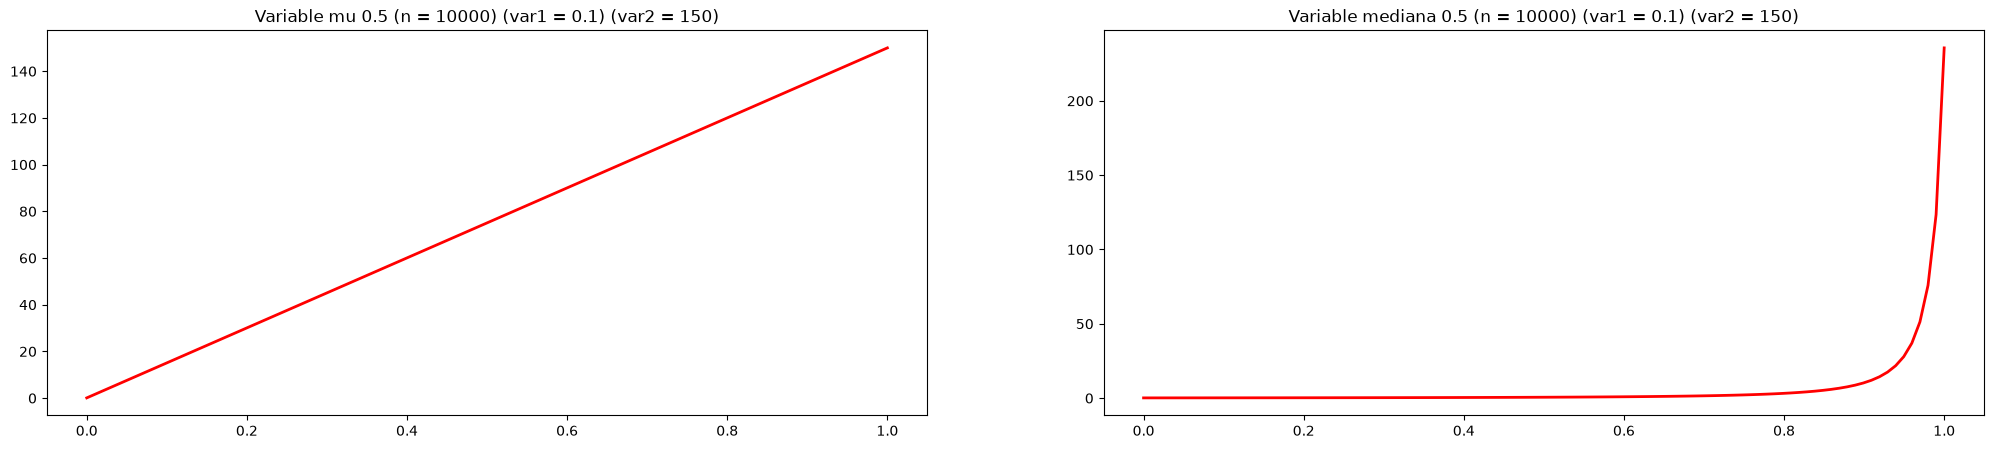

In [83]:
esilons = np.linspace(0, 1, 100)

for params in PARAMS:
    res_x = []
    res_med = []

    for eps in esilons:
        res_x.append(theor_var(params["n"], params["var1"], params["var2"], eps))
        res_med.append(n_sample_median_var(params["n"], params["var1"], params["var2"], eps))

    _, (ax1, ax2) = plt.subplots(1, 2, figsize=(25, 5))
    ax1.plot(esilons, res_x, color="red", lw=2)
    ax2.plot(esilons, res_med, color="red", lw=2)

    ax1.set_title(f"Variable mu 0.5 (n = {params["n"]}) (var1 = {params["var1"]}) (var2 = {params["var2"]})")

    ax2.set_title(f"Variable mediana 0.5 (n = {params["n"]}) (var1 = {params["var1"]}) (var2 = {params["var2"]})")

    plt.show()


In [84]:
NUM_SAMPLES = 10000

def gen_sample(n, mu, sigma, tau, epsilon):
    components = np.random.choice([0, 1], p=[1 - epsilon, epsilon], size=n)
    
    component_0 = np.random.normal(mu, sigma, size=n)
    component_1 = np.random.normal(mu, tau, size=n)
    
    return np.where(components == 0, component_0, component_1)

def run(params):
    global NUM_SAMPLES
    experiments = []

    for i in range(NUM_SAMPLES):
        experiments.append(gen_sample(params["n"], params["mu"], np.sqrt(params["var1"]), np.sqrt(params["var2"]), params["epsilon"]))

    experiments_variable_mean = []
    experiments_variable_var = []
    experiments_variable_quantile = []


    for i in range(NUM_SAMPLES):
        experiments_variable_mean.append(np.mean(experiments[i]))
        experiments_variable_var.append(np.var(experiments[i], ddof=1))
        experiments_variable_quantile.append(np.quantile(experiments[i], 0.5))

    experiments_variable_mean_norm = []
    experiments_variable_var_norm = []
    experiments_variable_quantile_norm = []

    mu = params["mu"]
    var = (1 - params["epsilon"]) * params["var1"] + params["epsilon"] * params["var2"]
    quantile_05 = mu

    for i in range(NUM_SAMPLES):
        experiments_variable_mean_norm.append(((experiments_variable_mean[i] - params["mu"]) * np.sqrt(params["n"])))
        experiments_variable_var_norm.append((experiments_variable_var[i] - var) * np.sqrt(params["n"]))
        experiments_variable_quantile_norm.append((experiments_variable_quantile[i] - quantile_05) * np.sqrt(params["n"]))



    _, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(25, 5))
    x = np.linspace(-6, 6, 500)

    ax1.hist(experiments_variable_mean_norm, bins=100, density=True, color="blue", edgecolor="black", alpha=0.6, label="Experimental")
    ax1.plot(x, stats.norm.pdf(x, loc=0, scale= np.sqrt(theor_var(params["n"], params["var1"], params["var2"], params["epsilon"]))), color="red", lw=2)
    ax1.set_title(f"Variable mu (n = {params["n"]}, mu = {params["mu"]}, var1 = {params["var1"]} , var2 = {params["var2"]}, epsilon = {params["epsilon"]}")
    ax1.legend()

    mu_4 = 3 * (1 - params["epsilon"]) * params["var1"]**2 + 3 * params["epsilon"] * params["var2"]**2
    var_theor = (1 - params["epsilon"]) * params["var1"] + params["epsilon"] * params["var2"]

    ax2.hist(experiments_variable_var_norm, bins=100, density=True, color="blue", edgecolor="black", alpha=0.6, label="Experimental")
    #ax2.plot(x, stats.norm.pdf(x, loc=0, scale=np.sqrt(mu_4 - var_theor**2)), color="red", lw=2)
    ax2.set_title(f"Variable var (n = {params["n"]}, mu = {params["mu"]}, var1 = {params["var1"]} , var2 = {params["var2"]}, epsilon = {params["epsilon"]}")
    ax2.legend()
    ax2.hist(experiments_variable_var_norm, bins=100, density=True, color="blue", edgecolor="black", alpha=0.6, label="Experimental")

    ax3.hist(experiments_variable_quantile_norm, bins=100, density=True, color="blue", edgecolor="black", alpha=0.6, label="Experimental")
    ax3.plot(x, stats.norm.pdf(x, loc=0, scale= np.sqrt(n_sample_median_var(params["n"], params["var1"], params["var2"], params["epsilon"]))), color="red", lw=2)
    ax3.set_title(f"Variable quantile 0.5 (n = {params["n"]}, mu = {params["mu"]}, var1 = {params["var1"]} , var2 = {params["var2"]}, epsilon = {params["epsilon"]}")
    ax3.legend()

    plt.show()

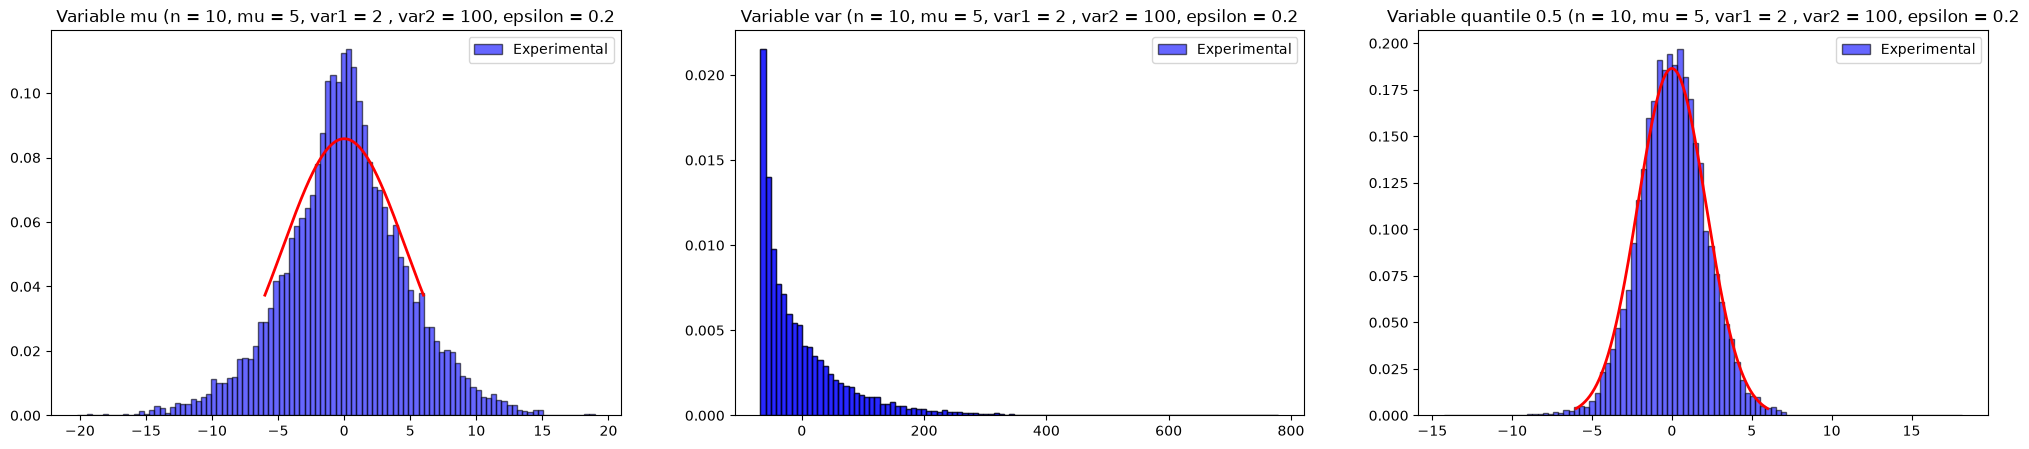

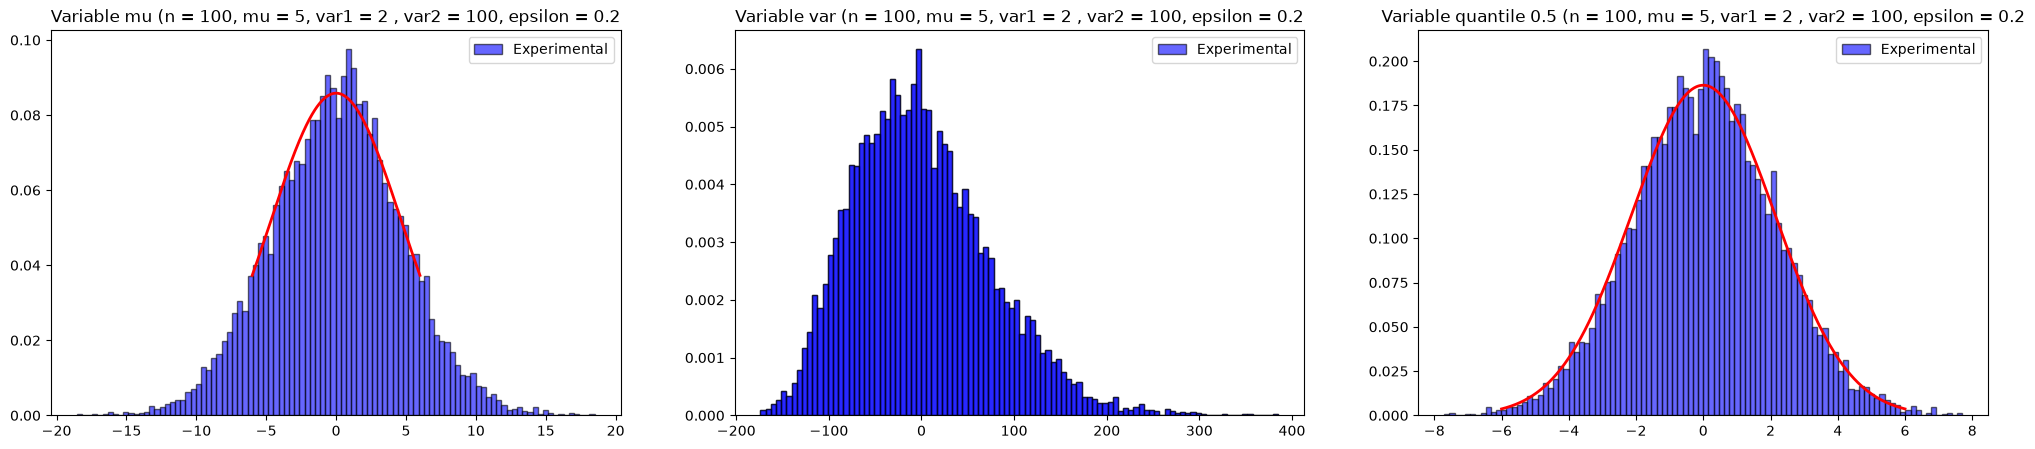

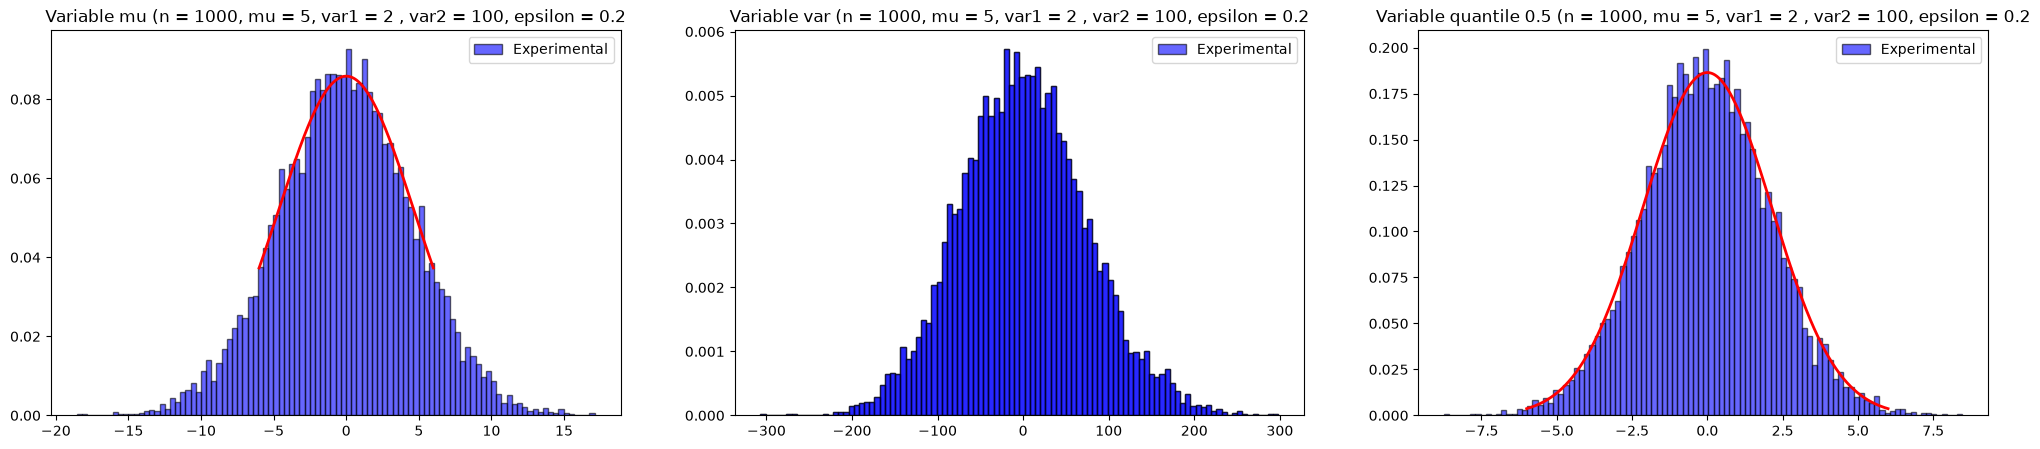

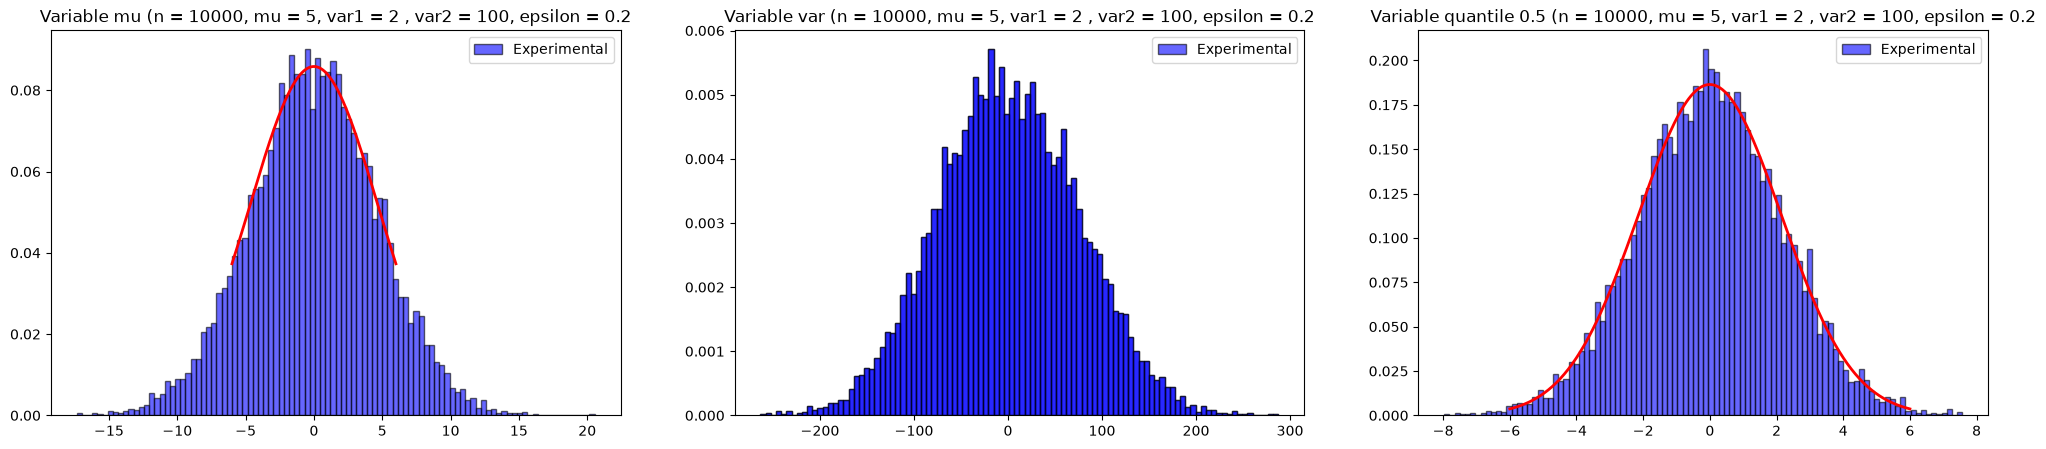

In [85]:
run({"n" : 10, "var1" : 2, "var2" : 100, "mu" : 5, "epsilon" : 0.2})
run({"n" : 100, "var1" : 2, "var2" : 100, "mu" : 5, "epsilon" : 0.2})
run({"n" : 1000, "var1" : 2, "var2" : 100, "mu" : 5, "epsilon" : 0.2})
run({"n" : 10000, "var1" : 2, "var2" : 100, "mu" : 5, "epsilon" : 0.2})
